## 1. **Transformer 모델 구성 요소 정의**

- Scaled Dot Product Attention    
- Multi-Head Attention    
- Encoder Layer   
- Encoder   
- Decoder Layer  
- Decoder   
- Positional Encoding  
Transformer 모델을 구성하는 핵심 모듈들을 정의합니다.  

In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import math

def make_attention_mask(pad_mask=None, q_len=None, causal=False):
    attn_mask = None

    if pad_mask is not None:
        batch_size, k_len = pad_mask.shape

        if q_len is None:
            q_len = k_len
        attn_mask = pad_mask.unsqueeze(1).unsqueeze(2)
        attn_mask = attn_mask.expand(batch_size, 1, q_len, k_len)

    if causal:
        if q_len is None:
            raise ValueError("causal=True일 때는 q_len이 필요합니다.")

        k_len = q_len
        causal_mask = torch.tril(torch.ones(q_len, k_len))

        # [1, 1, q_len, k_len]
        causal_mask = causal_mask.unsqueeze(0).unsqueeze(0)

        if attn_mask is None:
            attn_mask = causal_mask
        else:
            attn_mask = attn_mask * causal_mask
    return attn_mask

class ScaledDotProductAttention(nn.Module):
    def __init__(self, d_head):
        super().__init__()
        self.d_head = d_head

    def forward(self, Q, K, V, attn_mask=None):
        attention_scores = Q @ K.transpose(-2, -1)/ np.sqrt(self.d_head)

        if attn_mask is not None:
            attention_scores = attention_scores.masked_fill(attn_mask == 0, float("-inf"))

        attention_weights = F.softmax(attention_scores, dim=-1)
        context_vector = attention_weights @ V
        return context_vector

class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, num_heads):
        super().__init__()

        assert d_model % num_heads == 0, "d_model must be divisible by num_heads"

        self.d_model = d_model
        self.num_heads = num_heads
        self.d_head = d_model // num_heads

        self.W_q = nn.Linear(d_model, d_model, bias=False)
        self.W_k = nn.Linear(d_model, d_model, bias=False)
        self.W_v = nn.Linear(d_model, d_model, bias=False)
        self.out = nn.Linear(d_model, d_model, bias=False)

        self.attention = ScaledDotProductAttention(self.d_head)

    def forward(self, xq, xk, xv, attn_mask=None):
        batch_size = xq.size(0)
        Q = self.W_q(xq).view(batch_size, -1, self.num_heads, self.d_head).transpose(1, 2)
        K = self.W_k(xk).view(batch_size, -1, self.num_heads, self.d_head).transpose(1, 2)
        V = self.W_v(xv).view(batch_size, -1, self.num_heads, self.d_head).transpose(1, 2)

        # Apply Scaled Dot Product Attention
        x = self.attention(Q, K, V, attn_mask)

        # Concatenate and apply final linear
        head_output = x.transpose(1, 2).contiguous().view(batch_size, -1, self.d_model)
        out = self.out(head_output)
        return out

class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=5000):
        super().__init__()

        self.pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len).unsqueeze(1)

        div_term = torch.exp(torch.arange(0, d_model, 2).float() * -(torch.log(torch.tensor(10000.0)) / d_model))

        self.pe[:, 0::2] = torch.sin(position * div_term)
        self.pe[:, 1::2] = torch.cos(position * div_term)
        self.pe = self.pe.unsqueeze(0)

    def forward(self, x):
        return x + self.pe[:, :x.size(1), :]

class EncoderLayer(nn.Module):
    def __init__(self, d_model, num_heads):
        super().__init__()

        self.multihead_attn = MultiHeadAttention(d_model, num_heads)

        d_ff = d_model * 4

        self.W_ffn1 = nn.Parameter(torch.randn(d_model, d_ff))
        self.b_ffn1 = nn.Parameter(torch.randn(d_ff))
        self.W_ffn2 = nn.Parameter(torch.randn(d_ff, d_model))
        self.b_ffn2 = nn.Parameter(torch.randn(d_model))

        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)

    def forward(self, x, pad_mask=None):
        # Encoder Self-Attention: Q = K = V = x
        context_vector = self.multihead_attn(x, x, x, pad_mask)

        norm1_out = self.norm1(x + context_vector)

        f_out = F.relu(norm1_out @ self.W_ffn1 + self.b_ffn1)
        f_out = f_out @ self.W_ffn2 + self.b_ffn2

        final_out = self.norm2(norm1_out + f_out)
        return final_out

class Encoder(nn.Module):
    def __init__(self, num_layers, d_model, num_heads):
        super().__init__()
        self.layers = nn.ModuleList([EncoderLayer(d_model, num_heads) for _ in range(num_layers)])

    def forward(self, x, pad_mask=None):
        src_len = x.size(1)
        self_mask = make_attention_mask(pad_mask=pad_mask, q_len=src_len, causal=False)
        for layer in self.layers:
            x = layer(x, self_mask)
        return x

class DecoderLayer(nn.Module):
    def __init__(self, d_model, num_heads):
        super().__init__()

        self.self_attn = MultiHeadAttention(d_model, num_heads)
        self.cross_attn = MultiHeadAttention(d_model, num_heads)

        d_ff = d_model * 4

        self.W_ffn1 = nn.Parameter(torch.randn(d_model, d_ff))
        self.b_ffn1 = nn.Parameter(torch.randn(d_ff))
        self.W_ffn2 = nn.Parameter(torch.randn(d_ff, d_model))
        self.b_ffn2 = nn.Parameter(torch.randn(d_model))

        # Decoder는 Add & Norm이 3개
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.norm3 = nn.LayerNorm(d_model)

    def forward(self, x, encoder_out, tgt_self_mask=None, cross_mask=None):
        # 1. Masked Multi-Head Self-Attention
        self_attn_out = self.self_attn(x, x, x, attn_mask=tgt_self_mask)
        norm1_out = self.norm1(x + self_attn_out)

        # 2. Encoder-Decoder Attention, Cross Attention
        cross_attn_out = self.cross_attn(norm1_out, encoder_out, encoder_out, attn_mask=cross_mask)
        norm2_out = self.norm2(norm1_out + cross_attn_out)

        # 3. Feed Forward Network
        f_out = F.relu(norm2_out @ self.W_ffn1 + self.b_ffn1)
        f_out = f_out @ self.W_ffn2 + self.b_ffn2

        # 4. Add & Norm
        final_out = self.norm3(norm2_out + f_out)
        return final_out

class Decoder(nn.Module):
    def __init__(self, num_layers, d_model, num_heads):
        super().__init__()

        self.layers = nn.ModuleList([
            DecoderLayer(d_model, num_heads)
            for _ in range(num_layers)
        ])

    def forward(self, x, encoder_out, tgt_pad_mask=None, src_pad_mask=None):
        tgt_len = x.size(1)
        tgt_self_mask = make_attention_mask(pad_mask=tgt_pad_mask, q_len=tgt_len, causal=True)
        cross_mask = make_attention_mask(pad_mask=src_pad_mask, q_len=tgt_len, causal=False )

        for layer in self.layers:
            x = layer(x, encoder_out, tgt_self_mask=tgt_self_mask, cross_mask=cross_mask)

        # padding 위치 출력을 0으로 유지하고 싶을 경우
        if tgt_pad_mask is not None:
            x = x * tgt_pad_mask.unsqueeze(-1)
        return x

## **2. Transformer 모델 정의**

Encoder 및 Decoder를 조합하여 완전한 Transformer 모델을 구성하는 클래스를 정의합니다.

In [2]:
class Transformer(nn.Module):
    def __init__(self, d_model=512, nhead=8, num_encoder_layers=6, num_decoder_layers=6, vocab_size=None):
        super().__init__()
        self.d_model = d_model
        self.embedding = nn.Embedding(vocab_size, d_model)
        self.pos_encoder = PositionalEncoding(d_model)
        self.encoder = Encoder(num_encoder_layers, d_model, nhead)
        self.decoder = Decoder(num_decoder_layers, d_model, nhead)
        self.fc_out = nn.Linear(d_model, vocab_size)

    def forward(self, src, tgt, src_pad_mask=None, tgt_pad_mask=None):
        src_emb = self.pos_encoder(self.embedding(src) * math.sqrt(self.d_model))
        tgt_emb = self.pos_encoder(self.embedding(tgt) * math.sqrt(self.d_model))
        memory = self.encoder(x=src_emb, pad_mask=src_pad_mask)
        output = self.decoder(x=tgt_emb, encoder_out=memory, tgt_pad_mask=tgt_pad_mask, src_pad_mask=src_pad_mask)
        logits = self.fc_out(output)
        return logits

## **3. 데이터 로딩 및 기본 설정**

이 셀은 필요한 라이브러리를 임포트하고, 재현성을 위한 시드를 설정하며, 저장된 데이터를 로드하고 데이터셋의 기본적인 통계 정보를 출력합니다.

### 1) 데이터 로딩 & 통합 어휘 사전 구축


In [3]:
import os, math, pickle, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

PKL_PATH = "multi30k_data.pkl"
with open(PKL_PATH, "rb") as f:
    data = pickle.load(f)

print("학습용 문장 수 :", len(data["train_src_sentences"]))
print("검증용 문장 수 :", len(data["val_src_sentences"]))
print("src(영) vocab :", data["src_vocab_size"], " tgt(독) vocab :", data["tgt_vocab_size"])
print("src_max_len   :", data["src_max_len"], " tgt_max_len :", data["tgt_max_len"])

학습용 문장 수 : 29000
검증용 문장 수 : 1014
src(영) vocab : 5898  tgt(독) vocab : 7882
src_max_len   : 43  tgt_max_len : 47


## 통합 어휘 사전 구축 및 문장 인코딩

이 셀은 특수 토큰을 정의하고, Source(영어)와 Target(독일어) 언어의 모든 단어를 포함하는 통합 어휘 사전을 구축합니다. 또한, 문장을 숫자 ID 시퀀스로 변환하는 `encode` 함수를 사용하여 학습 및 검증 데이터를 인코딩합니다.

### 2) 단어 사전 구축(Vocabuary) 구축
- 특수토큰 등록

In [4]:
# ---- 통합 vocab (모델이 vocab_size 하나만 받으므로) ----
SPECIALS = ["<pad>", "<sos>", "<eos>", "<unk>"]
PAD_IDX, SOS_IDX, EOS_IDX, UNK_IDX = 0, 1, 2, 3

vocab = {tok: i for i, tok in enumerate(SPECIALS)}
for v in (data["src_vocab"], data["tgt_vocab"]):
    for tok in v:
        if tok not in vocab:
            vocab[tok] = len(vocab)
inv_vocab = {i: t for t, i in vocab.items()}
vocab_size = len(vocab)
print("통합 vocab_size :", vocab_size)

def encode(tokens):
    ids = [SOS_IDX] + [vocab.get(t, UNK_IDX) for t in tokens] + [EOS_IDX]
    return torch.tensor(ids, dtype=torch.long)

train_src_ids = [encode(s) for s in data["train_src_sentences"]]
train_tgt_ids = [encode(s) for s in data["train_tgt_sentences"]]
val_src_ids   = [encode(s) for s in data["val_src_sentences"]]
val_tgt_ids   = [encode(s) for s in data["val_tgt_sentences"]]


통합 vocab_size : 12999


## **4. Dataset 및 DataLoader 정의**

이 셀은 학습 데이터를 효율적으로 관리하기 위한 `TranslationDataset` 클래스와, 다양한 길이의 시퀀스를 배치로 묶고 패딩을 처리하는 `collate_fn` 함수를 정의합니다. 또한, 학습 및 검증을 위한 `DataLoader`를 초기화합니다.

In [5]:
class TranslationDataset(Dataset):
    def __init__(self, src_ids_list, tgt_ids_list):
        assert len(src_ids_list) == len(tgt_ids_list)
        self.src = src_ids_list
        self.tgt = tgt_ids_list
    def __len__(self):
        return len(self.src)
    def __getitem__(self, idx):
        return self.src[idx], self.tgt[idx]

def collate_fn(batch):
    src_seqs, tgt_seqs = zip(*batch)
    src = pad_sequence(src_seqs, batch_first=True, padding_value=PAD_IDX)
    tgt = pad_sequence(tgt_seqs, batch_first=True, padding_value=PAD_IDX)
    tgt_input = tgt[:, :-1]
    tgt_label = tgt[:, 1:]
    src_pad_mask = (src != PAD_IDX).long()
    tgt_pad_mask = (tgt_input != PAD_IDX).long()
    return src, tgt_input, tgt_label, src_pad_mask, tgt_pad_mask

BATCH_SIZE = 64

tr_src = train_src_ids
tr_tgt = train_tgt_ids

train_ds = TranslationDataset(tr_src, tr_tgt)
val_ds   = TranslationDataset(val_src_ids, val_tgt_ids)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  collate_fn=collate_fn)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn)

src, tgt_in, tgt_lb, src_m, tgt_m = next(iter(train_loader))
print("src", src.shape, " tgt_input", tgt_in.shape, " tgt_label", tgt_lb.shape)
print("총 학습 배치:", len(train_loader), " 검증 배치:", len(val_loader))

src torch.Size([64, 28])  tgt_input torch.Size([64, 32])  tgt_label torch.Size([64, 32])
총 학습 배치: 454  검증 배치: 16


## **5. 모델 하이퍼파라미터 설정 및 초기화**

이 셀은 Transformer 모델의 차원(D_MODEL), 헤드 수(N_HEADS), 인코더/디코더 레이어 수(NUM_ENC, NUM_DEC), 학습 에폭 수(NUM_EPOCHS), 학습률(LR)과 같은 하이퍼파라미터를 정의하고, Transformer 모델 인스턴스, 손실 함수(CrossEntropyLoss), 옵티마이저(Adam)를 초기화합니다.

- `make_attention_mask` 안 `causal_mask` 가 CPU 텐서로 만들어져서 디바이스 호환을 위해 CPU 학습.


In [6]:
D_MODEL    = 64
N_HEADS    = 4
NUM_ENC    = 2
NUM_DEC    = 2
NUM_EPOCHS = 5
LR         = 5e-4

model = Transformer(d_model=D_MODEL, nhead=N_HEADS, num_encoder_layers=NUM_ENC, num_decoder_layers=NUM_DEC,  vocab_size=vocab_size)
criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

n_params = sum(p.numel() for p in model.parameters())
print(f"파라미터 수 : {n_params:,}")

파라미터 수 : 1,908,807


## **6. 모델 학습 루프 및 평가 함수**

이 셀은 모델 학습을 위한 주 루프를 구현하고, 각 에폭에서 모델을 훈련하고 검증 데이터에 대한 성능을 평가합니다. `evaluate` 함수는 검증 손실을 계산하는 데 사용됩니다.

In [7]:
#%%time
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total, n = 0.0, 0
    for src, tgt_in, tgt_lb, src_m, tgt_m in loader:
        logits = model(src, tgt_in, src_pad_mask=src_m, tgt_pad_mask=tgt_m)
        loss = criterion(logits.reshape(-1, vocab_size), tgt_lb.reshape(-1))
        total += loss.item() * src.size(0)
        n     += src.size(0)
    return total / n

train_losses, val_losses = [], []

for epoch in range(1, NUM_EPOCHS + 1):
    model.train()
    running = 0.0
    print(f"--- Epoch {epoch}/{NUM_EPOCHS} ---")
    for batch_idx, (src, tgt_in, tgt_lb, src_m, tgt_m) in enumerate(train_loader):
        optimizer.zero_grad()
        logits = model(src, tgt_in, src_pad_mask=src_m, tgt_pad_mask=tgt_m)
        loss = criterion(logits.reshape(-1, vocab_size), tgt_lb.reshape(-1))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        running += loss.item()
        if (batch_idx + 1) % 20 == 0:
            print(f"  step {batch_idx+1:4d}/{len(train_loader)}  loss={loss.item():.4f}")
    train_loss = running / len(train_loader)
    val_loss   = evaluate(model, val_loader)
    train_losses.append(train_loss); val_losses.append(val_loss)
    print(f"Epoch {epoch}  train_loss={train_loss:.4f}  val_loss={val_loss:.4f}\n")

--- Epoch 1/5 ---
  step   20/454  loss=8.7022
  step   40/454  loss=7.7841
  step   60/454  loss=6.9242
  step   80/454  loss=6.2454
  step  100/454  loss=5.7580
  step  120/454  loss=5.4014
  step  140/454  loss=5.3308
  step  160/454  loss=5.1638
  step  180/454  loss=5.0322
  step  200/454  loss=4.9361
  step  220/454  loss=4.8536
  step  240/454  loss=4.7530
  step  260/454  loss=4.5460
  step  280/454  loss=4.4279
  step  300/454  loss=4.5308
  step  320/454  loss=4.5726
  step  340/454  loss=4.5144
  step  360/454  loss=4.4806
  step  380/454  loss=4.2644
  step  400/454  loss=4.4655
  step  420/454  loss=4.2762
  step  440/454  loss=4.2935
Epoch 1  train_loss=5.3170  val_loss=4.1757

--- Epoch 2/5 ---
  step   20/454  loss=4.0497
  step   40/454  loss=4.1934
  step   60/454  loss=3.9765
  step   80/454  loss=3.9544
  step  100/454  loss=4.1166
  step  120/454  loss=3.9059
  step  140/454  loss=3.9027
  step  160/454  loss=3.9429
  step  180/454  loss=3.9164
  step  200/454  los

## **7. 학습 곡선 시각화**

이 셀은 각 에폭에서 기록된 학습 손실과 검증 손실을 사용하여 학습 곡선을 플로팅합니다. 이를 통해 모델의 학습 진행 상황과 과적합 여부를 시각적으로 확인할 수 있습니다.

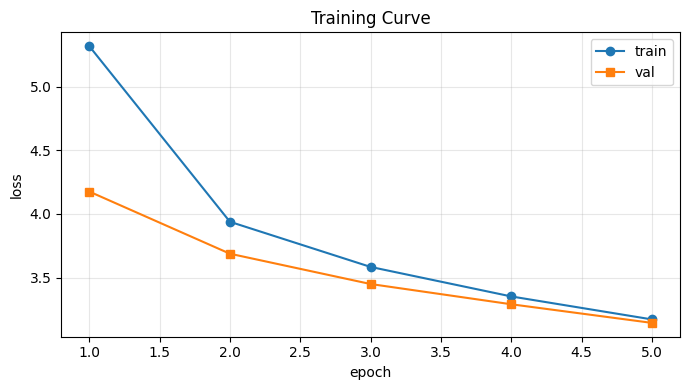

In [8]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(train_losses)+1), train_losses, "o-", label="train")
plt.plot(range(1, len(val_losses)+1),   val_losses,   "s-", label="val")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.title("Training Curve")
plt.grid(True, alpha=0.3); plt.legend(); plt.tight_layout()
plt.show()

## **8. 추론(Greedy Decoding) 함수 정의**

이 셀은 학습된 Transformer 모델을 사용하여 번역을 수행하는 `greedy_decode` 함수를 정의합니다. 이 함수는 소스 문장을 입력받아, 토큰을 하나씩 예측하며 타겟 시퀀스를 생성합니다.

In [9]:
@torch.no_grad()
def greedy_decode(model, src_tokens, max_len=50):
    model.eval()
    src_ids = encode(src_tokens).unsqueeze(0)
    src_mask = (src_ids != PAD_IDX).long()

    ys = torch.tensor([[SOS_IDX]], dtype=torch.long)
    for _ in range(max_len - 1):
        tgt_mask = (ys != PAD_IDX).long()
        logits = model(src_ids, ys, src_pad_mask=src_mask, tgt_pad_mask=tgt_mask)
        next_id = logits[:, -1, :].argmax(-1, keepdim=True)
        ys = torch.cat([ys, next_id], dim=1)
        if next_id.item() == EOS_IDX:
            break

    out_ids = ys[0].tolist()[1:]
    if EOS_IDX in out_ids:
        out_ids = out_ids[:out_ids.index(EOS_IDX)]
    return [inv_vocab[i] for i in out_ids]


## **9. 검증 데이터 일부로 번역 추론**

이 셀은 검증 데이터셋에서 무작위로 선택된 몇 가지 예제를 사용하여 `greedy_decode` 함수를 통해 번역을 수행하고, 원문(영어), 정답(독일어), 모델 번역(번역) 결과를 출력하여 모델의 성능을 정성적으로 확인합니다.

In [10]:
NUM_DEMO = 8
demo_idxs = random.sample(range(len(data["val_src_sentences"])), NUM_DEMO)
for i, idx in enumerate(demo_idxs, 1):
    src_tok = data["val_src_sentences"][idx]
    ref_tok = data["val_tgt_sentences"][idx]
    hyp_tok = greedy_decode(model, src_tok, max_len=data["tgt_max_len"])
    print(f"[{i}] idx={idx}")
    print("  영  어 :", " ".join(src_tok))
    print("  독일어 :", " ".join(ref_tok))
    print("  번  역 :", " ".join(hyp_tok))
    print()

[1] idx=654
  영  어 : two men smoking outside of a park .
  독일어 : zwei männer rauchen außerhalb eines parks .
  번  역 : zwei männer stehen sich auf einem gebäude .

[2] idx=114
  영  어 : a blue jeep drive into deep , muddy water .
  독일어 : ein blauer jeep fährt in tiefes , schlammiges wasser .
  번  역 : ein kind in ein paar in den händen .

[3] idx=25
  영  어 : two dogs play with an orange toy in tall grass .
  독일어 : zwei hunde spielen im hohen gras mit einem orangen spielzeug .
  번  역 : zwei hunde spielen mit einem <unk> in einem <unk> .

[4] idx=759
  영  어 : a group of girls are playing in a water fountain in the sun .
  독일어 : eine gruppe von mädchen spielt in einem springbrunnen in der sonne .
  번  역 : eine gruppe mädchen spielt in einem park in der hand .

[5] idx=281
  영  어 : a soccer team player in a green shirt is running off the field .
  독일어 : ein fußballspieler in einem grünen trikot läuft vom spielfeld .
  번  역 : ein baseballspieler in einem grünen oberteil läuft durch einen ball 

## 검증셋 전체에 대한 번역 추론

이 셀은 검증 데이터셋의 모든 문장에 대해 `greedy_decode` 함수를 사용하여 번역을 수행합니다. 생성된 모든 번역 결과(`hyps_tokens`)와 원본 참조 문장(`refs_tokens`)을 저장하여 BLEU 점수 계산에 활용합니다.

## **10. BLEU 점수 계산**

BLEU 는 모델 번역과 정답 사이의 n-gram 일치율을 0~100 점으로 나타내는 지표.

- **sacrebleu** (권장): WMT/논문 표준. 토큰화 방식까지 표준화된 corpus-level BLEU.

라이브러리 설치가 필요 → `pip install sacrebleu`

> 참고:
> 지금처럼 작게 + subset + 짧게 학습하면 5 - 15 가 일반적입니다.
Multi30k 영-독은 충분히 학습(전체 29k, d_model 256+, 6/6 layers, 10+ epoch)하면 BLEU 30이상 가능합니다.
> 코드를 수정하여 BLEU를 높여보세요.



In [11]:
# 검증셋 전체 추론
hyps_tokens, refs_tokens = [], []
t0 = time.time()
for i, (src_tok, ref_tok) in enumerate(zip(data["val_src_sentences"], data["val_tgt_sentences"])):
    hyp_tok = greedy_decode(model, src_tok, max_len=data["tgt_max_len"])
    hyps_tokens.append(hyp_tok)
    refs_tokens.append(ref_tok)
    if (i + 1) % 200 == 0:
        print(f"  decoded {i+1}/{len(data['val_src_sentences'])}  ({time.time()-t0:.1f}s)")
print(f"완료: {len(hyps_tokens)} 문장, {time.time()-t0:.1f}s")


  decoded 200/1014  (10.8s)
  decoded 400/1014  (20.9s)
  decoded 600/1014  (31.0s)
  decoded 800/1014  (41.0s)
  decoded 1000/1014  (51.7s)
완료: 1014 문장, 52.3s


## sacrebleu 라이브러리 설치

이 셀은 BLEU 점수 계산을 위해 필요한 `sacrebleu` 라이브러리를 설치합니다. `sacrebleu`는 표준화된 토큰화 방식을 사용하여 번역 품질을 평가합니다.

In [12]:
!pip install sacrebleu

## **11. BLEU 점수 계산 및 출력**

이 셀은 `sacrebleu` 라이브러리를 사용하여 모델이 생성한 번역 결과와 참조 번역 간의 BLEU 점수를 계산합니다. `simple_detok` 함수를 사용하여 토큰화된 문장을 다시 텍스트로 변환한 후 BLEU 점수를 출력합니다.

In [13]:
import sacrebleu

def simple_detok(tokens):
    text = " ".join(tokens)
    text = text.replace(" .", ".")
    text = text.replace(" ,", ",")
    text = text.replace(" !", "!")
    text = text.replace(" ?", "?")
    text = text.replace(" ' ", "'")
    return text

hyps_str = [simple_detok(toks) for toks in hyps_tokens]
refs_str = [simple_detok(toks) for toks in refs_tokens]
bleu = sacrebleu.corpus_bleu(hyps_str, [refs_str])
print("sacrebleu :", bleu.score)
print(bleu)

sacrebleu : 10.300968307304911
BLEU = 10.30 37.3/14.5/6.7/3.1 (BP = 1.000 ratio = 1.117 hyp_len = 14615 ref_len = 13084)


## Transformer 논문 vs MyTransformers 설정 비교

| 항목           | Transformer 논문                                   | MyTransformers 설정                               |
|:---------------|:---------------------------------------------------|:--------------------------------------------------|
| 데이터셋       | WMT 2014 English-German (450만 쌍의 문장)           | Multi30k 독일어-영어 번역작업                     |
|                | English-French (3,600만개 문장 32,000개 단어)        | WMT보다는 훨씬 작지만 CPU에서 동작                |
| 토큰화         | BPE / Word-piece                                   | 단어 수준     |
| 하드웨어       | 8 × NVIDIA P100 GPU                                | CPU                                               |
| 스케줄         | 기본모델 : 100,000 스텝 또는 12시간 훈련             | 1시간 이내                                        |
|                | 대규모 모델 : 300,000 스텝(3.5일) 훈련             |                                                   |
| Optimizer      | Adam (β₁ = 0.9, β₂ = 0.98, ε = 10⁻⁹)               | Adam                                              |
| Learning Rate  | Warmup 후 inverse square root decay                | Fixed learning rate (5e-4)                        |
| Warmup Steps   | 4,000                                              | 미적용 (Not applied)                              |
| Dropout        | 0.1 (Add & Norm 이전)                              | 미적용                                            |
| Label Smoothing| 0.1                                                | 미적용                                            |
| 주요 결과      | 적은 훈련 비용으로 기존 SOTA보다 높은 BLEU 달성    | 10.3 (하이퍼파라미터로 추가개선가능)             |